# Student_Score_Analysis
## Part B - Practical(Python Programming)
Dataset: `students_scores.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline

df = pd.read_csv("students_scores.csv")
print("Shape:", df.shape)
df.head()

Shape: (5000, 7)


,Student_ID,Age,Math_Score,Science_Score,English_Score,Hours_Studied,Pass_Fail
0,1,17,75,54,51,6.0,1
1,2,18,66,57,64,6.3,1
2,3,15,72,58,65,6.1,1
3,4,17,72,65,58,5.2,1
4,5,17,56,63,60,4.6,0


## Step 1: Measures of Central Tendency & Dispersion

In [2]:
# Math_Score: mean, median, mode
math_mean = df["Math_Score"].mean()
math_median = df["Math_Score"].median()
math_mode = df["Math_Score"].mode()[0]

print("Math Mean   :", round(math_mean, 2))
print("Math Median :", math_median)
print("Math Mode   :", math_mode)

Math Mean   : 64.74
Math Median : 65.0
Math Mode   : 62


**Interpretation:** The three values are close, so the scores are symmetric and a typical student scores about 65.

In [3]:
# Science_Score: range, variance, standard deviation
sci_range = df["Science_Score"].max() - df["Science_Score"].min()
sci_var = df["Science_Score"].var()
sci_std = df["Science_Score"].std()

print("Science Range    :", sci_range)
print("Science Variance :", round(sci_var, 2))
print("Science Std Dev  :", round(sci_std, 2))

Science Range    : 86
Science Variance : 204.63
Science Std Dev  : 14.31


**Interpretation:** The scores are widely spread, and most students are within about 14 marks of the average.

## Step 2: Probability Basics

In [4]:
# Probability of passing
p_pass = (df["Pass_Fail"] == 1).sum() / len(df)
print("P(Pass) =", round(p_pass, 4))

P(Pass) = 0.688


**Interpretation:** About 69% of students passed and about 31% failed.

In [5]:
# Contingency table: Pass_Fail vs Hours_Studied > 5
df["Hours_gt_5"] = df["Hours_Studied"] > 5
table = pd.crosstab(df["Pass_Fail"], df["Hours_gt_5"])
table.columns = ["Hours <= 5", "Hours > 5"]
table.index = ["Fail (0)", "Pass (1)"]
table

,Hours <= 5,Hours > 5
Fail (0),1367,193
Pass (1),1237,2203


**Interpretation:** Among those who studied more than 5 hours, 2203 passed and only 193 failed. Among the others, the split is much more balanced (1237 pass vs 1367 fail).

In [6]:
# Conditional probability P(Pass | Hours_Studied > 5)
pass_and_hours = ((df["Pass_Fail"] == 1) & (df["Hours_gt_5"])).sum()
hours_gt5 = df["Hours_gt_5"].sum()
p_pass_given_hours = pass_and_hours / hours_gt5
print("P(Pass | Hours_Studied > 5) =", round(p_pass_given_hours, 4))

P(Pass | Hours_Studied > 5) = 0.9194


**Interpretation:** Students who study more than 5 hours have about a 92% chance of passing, compared with 69% overall.

## Step 3: Distribution & Visualization

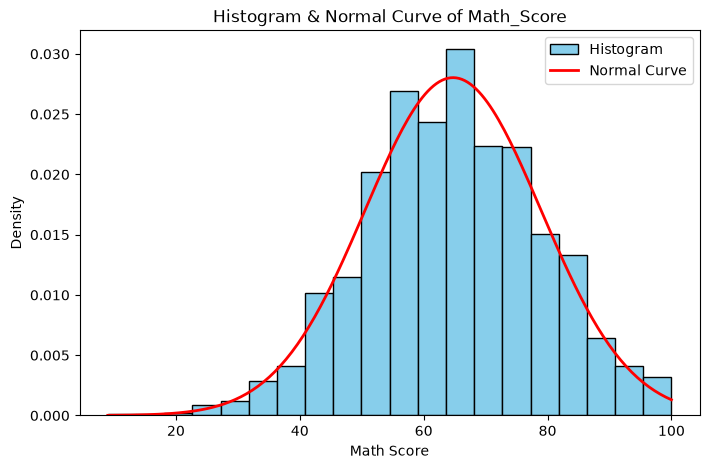

In [7]:
# Histogram & Normal curve for Math_Score
mu = df["Math_Score"].mean()
sigma = df["Math_Score"].std()

plt.figure(figsize=(8, 5))
plt.hist(df["Math_Score"], bins=20, density=True, color="skyblue", edgecolor="black", label="Histogram")
x = np.linspace(df["Math_Score"].min(), df["Math_Score"].max(), 200)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="red", linewidth=2, label="Normal Curve")
plt.title("Histogram & Normal Curve of Math_Score")
plt.xlabel("Math Score")
plt.ylabel("Density")
plt.legend()
plt.show()

**Interpretation:** The histogram is bell-shaped and fits the red curve, so Math scores are approximately normal.

In [8]:
# Skewness & Kurtosis of Science_Score
sci_skew = stats.skew(df["Science_Score"])
sci_kurt = stats.kurtosis(df["Science_Score"])   # excess kurtosis

print("Science Skewness :", round(sci_skew, 4))
print("Science Kurtosis :", round(sci_kurt, 4))

Science Skewness : -0.023
Science Kurtosis : -0.0812


**Interpretation:** Both are near 0, so the Science distribution is symmetric and normal-like.

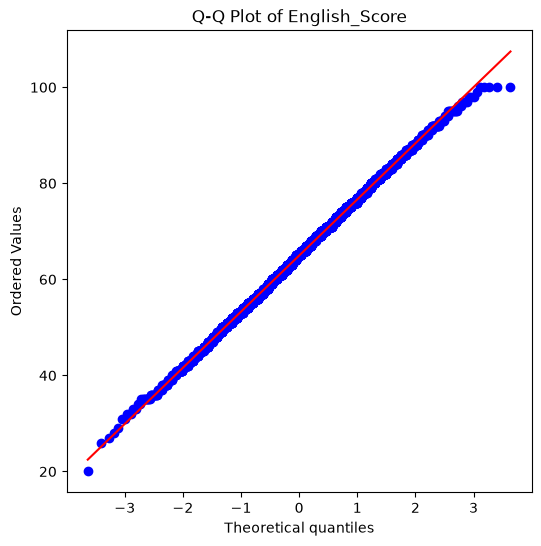

In [15]:
# Q-Q Plot for English_Score
plt.figure(figsize=(6, 6))
stats.probplot(df["English_Score"], dist="norm", plot=plt)
plt.title("Q-Q Plot of English_Score")
plt.show()

**Interpretation:** The points lie close to the line, so English scores are approximately normal.

## Step 4: Linear Algebra Mini Task

In [10]:
# First 5 students as vectors
math_vec = df["Math_Score"].head(5).values
sci_vec = df["Science_Score"].head(5).values

print("Math vector    :", math_vec)
print("Science vector :", sci_vec)

Math vector    : [75 66 72 72 56]
Science vector : [54 57 58 65 63]


**Interpretation:** The Math and Science vectors have similar values, which hints that good Math students also do well in Science.

In [11]:
# Dot product
dot = np.dot(math_vec, sci_vec)
print("Dot Product :", dot)

Dot Product : 20196


**Interpretation:** A large positive value, so the vectors point in the same direction.

In [12]:
# Norm 1 and Norm 2 of Math vector
norm1 = np.linalg.norm(math_vec, 1)
norm2 = np.linalg.norm(math_vec, 2)

print("Norm 1 (Math) :", norm1)
print("Norm 2 (Math) :", round(norm2, 4))

Norm 1 (Math) : 341.0
Norm 2 (Math) : 153.2482


**Interpretation:** Norm 1 is the sum of the Math scores and Norm 2 is the vector’s length. Both show the overall level of the Math scores.

In [13]:
# Angle between the two vectors
cos_theta = dot / (np.linalg.norm(math_vec) * np.linalg.norm(sci_vec))
angle_rad = np.arccos(cos_theta)
angle_deg = np.degrees(angle_rad)

print("Cos(theta)      :", round(cos_theta, 6))
print("Angle (radians) :", round(angle_rad, 4))
print("Angle (degrees) :", round(angle_deg, 4))

Cos(theta)      : 0.989923
Angle (radians) : 0.1421
Angle (degrees) : 8.1408


**Interpretation:** The angle is very small, so the Math and Science vectors are almost parallel.

## Key Insights
- About 69% of students passed.
- Students studying more than 5 hours have about 92% chance of passing.
- Science score distribution is almost normal (skewness and kurtosis near 0).
- Math and Science score vectors have a small angle (~8°), so their patterns are very similar.